# AI-Based Landing Zone Safety Classification Using Drone Imagery — v2
## Capstone Project

1. **Hyperparameter tuning** — GridSearchCV (stratified CV) for every scikit-learn model, plus a manual CV grid search for the from-scratch models.
2. **Self-built models** — Logistic Regression, Decision Tree and Random Forest written from scratch with NumPy (no sklearn model classes).
3. **Multi-seed runs** — the whole pipeline (split → scale → tune → evaluate) is repeated for 5 seeds; results are reported as mean ± std.
4. Same downstream analysis as before: feature importance, probability → risk tiers, landing-action policy, artificial-grid safety heatmap.

Label convention used here: `label = 1` → **Safe**, `label = 0` → **Unsafe**.

In [1]:
import warnings, time, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

SEEDS = [0, 1, 2, 42, 123]          # >= 5 seeds (add more if you like)
TEST_SIZE = 0.2
FAST = False                          # True -> smaller grids / forests (quick check)
print("Imports OK | seeds:", SEEDS)

Imports OK | seeds: [0, 1, 2, 42, 123]


## 1. Load data (same Google Sheet as the original notebook)

In [2]:
URL = "https://docs.google.com/spreadsheets/d/1tCQf9YVzj8zET1bjTlettAV5WfyeNpo4EBEjo5H1Z9Y/export?format=csv&gid=0"
LOCAL = "landing_zone_data.csv"       # optional local fallback with the same columns

try:
    df = pd.read_csv(URL)
    print("Loaded from Google Sheet")
except Exception as e:
    if os.path.exists(LOCAL):
        df = pd.read_csv(LOCAL)
        print("Sheet not reachable -> loaded local file:", LOCAL)
    else:
        raise RuntimeError("Could not load the data. Check the Sheet link or upload "
                           f"'{LOCAL}' next to the notebook.") from e

FEATURES = ["slope_deg", "roughness", "edge_density", "ndvi_mean",
            "shadow_fraction", "brightness_std", "object_density", "confidence_score"]
TARGET = "label"
df = df[FEATURES + [TARGET]].dropna().drop_duplicates().reset_index(drop=True)

print("Shape:", df.shape)
print(df[TARGET].value_counts(normalize=True).rename("class share"))
df.head()

Loaded from Google Sheet
Shape: (3000, 9)
label
1    0.55
0    0.45
Name: class share, dtype: float64


,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score,label
0,10.483571,0.066756,0.099523,0.398224,0.297286,0.067727,0.182327,0.741485,1
1,7.308678,0.105711,0.377215,0.669015,0.057829,0.147740,0.272118,0.837913,1
2,11.238443,0.535800,0.067437,0.438767,0.198451,0.132821,0.140229,0.802620,0
3,15.615149,0.159571,0.182308,0.081362,0.379600,0.124568,0.170602,0.777006,1
4,6.829233,0.122880,0.129803,0.492456,0.110414,0.156328,0.044424,0.885057,1


## 2. Models written from scratch (NumPy only)
* `MyLogisticRegression` — batch gradient descent, L2 penalty
* `MyDecisionTree` — CART with Gini impurity, quantile candidate thresholds
* `MyRandomForest` — bagging + random feature subsets on top of `MyDecisionTree`

In [3]:
class MyLogisticRegression:
    def __init__(self, lr=0.1, n_iter=800, l2=0.0):
        self.lr, self.n_iter, self.l2 = lr, n_iter, l2

    @staticmethod
    def _sigmoid(z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -35, 35)))

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        n, d = X.shape
        self.w, self.b = np.zeros(d), 0.0
        for _ in range(self.n_iter):
            p = self._sigmoid(X @ self.w + self.b)
            err = p - y
            self.w -= self.lr * (X.T @ err / n + self.l2 * self.w)
            self.b -= self.lr * err.mean()
        return self

    def predict_proba(self, X):
        p1 = self._sigmoid(np.asarray(X, float) @ self.w + self.b)
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


class MyDecisionTree:
    def __init__(self, max_depth=6, min_samples_split=10, min_samples_leaf=3,
                 max_features=None, n_thresholds=24, random_state=0):
        self.max_depth, self.min_samples_split = max_depth, min_samples_split
        self.min_samples_leaf, self.max_features = min_samples_leaf, max_features
        self.n_thresholds, self.random_state = n_thresholds, random_state

    @staticmethod
    def _gini(pos, n):
        p = pos / n
        return 2 * p * (1 - p)

    def fit(self, X, y):
        self.X_, self.y_ = np.asarray(X, float), np.asarray(y, int)
        self.rng_ = np.random.RandomState(self.random_state)
        self.n_features_ = self.X_.shape[1]
        self.importances_ = np.zeros(self.n_features_)
        self.root_ = self._grow(np.arange(len(self.y_)), 0)
        s = self.importances_.sum()
        self.feature_importances_ = self.importances_ / s if s > 0 else self.importances_
        del self.X_, self.y_
        return self

    def _n_feats(self):
        mf = self.max_features
        if mf is None: return self.n_features_
        if mf == "sqrt": return max(1, int(np.sqrt(self.n_features_)))
        return int(mf)

    def _best_split(self, idx):
        X, y = self.X_[idx], self.y_[idx]
        n, pos = len(idx), y.sum()
        parent = self._gini(pos, n)
        best = (None, None, 0.0)                     # feature, threshold, gain
        feats = self.rng_.choice(self.n_features_, self._n_feats(), replace=False)
        for f in feats:
            col = X[:, f]
            cand = np.unique(np.quantile(col, np.linspace(0.04, 0.96, self.n_thresholds)))
            mask = col[:, None] <= cand[None, :]
            nl = mask.sum(0); nr = n - nl
            ok = (nl >= self.min_samples_leaf) & (nr >= self.min_samples_leaf)
            if not ok.any(): continue
            pl = (mask * y[:, None]).sum(0)
            pr = pos - pl
            with np.errstate(divide="ignore", invalid="ignore"):
                g = parent - (nl / n) * self._gini(pl, nl) - (nr / n) * self._gini(pr, nr)
            g = np.where(ok, g, -np.inf)
            j = int(np.argmax(g))
            if g[j] > best[2]:
                best = (f, cand[j], g[j])
        return best

    def _grow(self, idx, depth):
        y = self.y_[idx]
        node = {"p": y.mean()}
        if depth >= self.max_depth or len(idx) < self.min_samples_split or y.min() == y.max():
            return node
        f, t, gain = self._best_split(idx)
        if f is None or gain <= 1e-12:
            return node
        self.importances_[f] += gain * len(idx)
        left = self.X_[idx, f] <= t
        node.update(f=f, t=t,
                    l=self._grow(idx[left], depth + 1),
                    r=self._grow(idx[~left], depth + 1))
        return node

    def _predict_idx(self, node, X, idx, out):
        if "f" not in node:
            out[idx] = node["p"]; return
        left = X[idx, node["f"]] <= node["t"]
        self._predict_idx(node["l"], X, idx[left], out)
        self._predict_idx(node["r"], X, idx[~left], out)

    def predict_proba(self, X):
        X = np.asarray(X, float)
        out = np.zeros(len(X))
        self._predict_idx(self.root_, X, np.arange(len(X)), out)
        return np.column_stack([1 - out, out])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


class MyRandomForest:
    def __init__(self, n_estimators=100, max_depth=8, min_samples_leaf=3,
                 min_samples_split=10, max_features="sqrt", random_state=0):
        self.n_estimators, self.max_depth = n_estimators, max_depth
        self.min_samples_leaf, self.min_samples_split = min_samples_leaf, min_samples_split
        self.max_features, self.random_state = max_features, random_state

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, int)
        rng = np.random.RandomState(self.random_state)
        self.trees_ = []
        for i in range(self.n_estimators):
            boot = rng.randint(0, len(y), len(y))
            tree = MyDecisionTree(self.max_depth, self.min_samples_split, self.min_samples_leaf,
                                  self.max_features, random_state=rng.randint(1 << 30))
            self.trees_.append(tree.fit(X[boot], y[boot]))
        self.feature_importances_ = np.mean([t.feature_importances_ for t in self.trees_], axis=0)
        return self

    def predict_proba(self, X):
        p1 = np.mean([t.predict_proba(X)[:, 1] for t in self.trees_], axis=0)
        return np.column_stack([1 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

print("From-scratch models defined")

From-scratch models defined


### Sanity check — scratch models vs scikit-learn (default settings, one split)

In [4]:
Xa, ya = df[FEATURES].values, df[TARGET].values
Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=TEST_SIZE, stratify=ya, random_state=42)
sc = StandardScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)

pairs = {
    "LogReg  (sklearn)": LogisticRegression(max_iter=1000).fit(Xtr_s, ytr),
    "LogReg  (scratch)": MyLogisticRegression().fit(Xtr_s, ytr),
    "DecTree (sklearn)": DecisionTreeClassifier(max_depth=6, random_state=42).fit(Xtr_s, ytr),
    "DecTree (scratch)": MyDecisionTree(max_depth=6, random_state=42).fit(Xtr_s, ytr),
    "RandFor (sklearn)": RandomForestClassifier(n_estimators=50, max_depth=8, random_state=42).fit(Xtr_s, ytr),
    "RandFor (scratch)": MyRandomForest(n_estimators=50, max_depth=8, random_state=42).fit(Xtr_s, ytr),
}
for k, m in pairs.items():
    print(f"{k}: accuracy = {accuracy_score(yte, m.predict(Xte_s)):.4f}")

LogReg  (sklearn): accuracy = 0.7150
LogReg  (scratch): accuracy = 0.7133
DecTree (sklearn): accuracy = 0.6367
DecTree (scratch): accuracy = 0.6233
RandFor (sklearn): accuracy = 0.6850
RandFor (scratch): accuracy = 0.6933


## 3. Hyperparameter search spaces

In [5]:
SK_GRIDS = {
    "LogReg (sklearn)": (LogisticRegression(max_iter=2000),
        {"C": [0.01, 0.1, 1, 10, 100], "penalty": ["l2"], "solver": ["lbfgs"]}),
    "DecTree (sklearn)": (DecisionTreeClassifier(),
        {"max_depth": [3, 4, 5, 6, 8, 10], "min_samples_leaf": [1, 5, 10, 20],
         "criterion": ["gini", "entropy"]}),
    "RandFor (sklearn)": (RandomForestClassifier(n_jobs=-1),
        {"n_estimators": [100, 200, 300], "max_depth": [4, 6, 8, None],
         "min_samples_leaf": [1, 3, 5], "max_features": ["sqrt", 0.5]}),
}
SCRATCH_GRIDS = {
    "LogReg (scratch)": (MyLogisticRegression,
        {"lr": [0.05, 0.2], "l2": [0.0, 0.01, 0.1], "n_iter": [800]}),
    "DecTree (scratch)": (MyDecisionTree,
        {"max_depth": [3, 5, 7, 10], "min_samples_leaf": [3, 10, 20]}),
    "RandFor (scratch)": (MyRandomForest,
        {"n_estimators": [40], "max_depth": [6, 10], "min_samples_leaf": [3, 8]}),
}
if FAST:
    SK_GRIDS["RandFor (sklearn)"][1].update(n_estimators=[100], max_depth=[6, None], min_samples_leaf=[1, 5])
    SCRATCH_GRIDS["RandFor (scratch)"][1].update(max_depth=[6], min_samples_leaf=[5])

from itertools import product
def grid_iter(grid):
    keys = list(grid)
    for vals in product(*[grid[k] for k in keys]):
        yield dict(zip(keys, vals))

def scratch_grid_search(cls, grid, X, y, seed, folds=3):
    """Manual stratified-CV grid search, scored by ROC-AUC (same criterion as GridSearchCV)."""
    skf = StratifiedKFold(folds, shuffle=True, random_state=seed)
    best, best_s = None, -1
    for params in grid_iter(grid):
        scores = []
        for a, b in skf.split(X, y):
            kw = dict(params)
            if cls is not MyLogisticRegression: kw["random_state"] = seed
            m = cls(**kw).fit(X[a], y[a])
            scores.append(roc_auc_score(y[b], m.predict_proba(X[b])[:, 1]))
        s = np.mean(scores)
        if s > best_s: best, best_s = params, s
    return best, best_s

def metrics(y_true, proba):
    pred = (proba >= 0.5).astype(int)
    return dict(Accuracy=accuracy_score(y_true, pred),
                Precision=precision_score(y_true, pred, zero_division=0),
                Recall=recall_score(y_true, pred, zero_division=0),
                F1=f1_score(y_true, pred, zero_division=0),
                ROC_AUC=roc_auc_score(y_true, proba))

print("Grids ready")

Grids ready


## 4. Multi-seed experiment
For **each seed** the pipeline is: stratified 80/20 split → fit scaler on train only → evaluate the **untuned** sklearn baselines → tune every model with CV on the **training set only** → evaluate on the held-out test set.
Nothing from the test set is used for tuning.

In [6]:
rows, best_params_rows = [], []
t0 = time.time()

for seed in SEEDS:
    Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=TEST_SIZE, stratify=ya, random_state=seed)
    sc = StandardScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
    cv = StratifiedKFold(5, shuffle=True, random_state=seed)

    # --- untuned sklearn baselines (what the original notebook did) ---
    base = {
        "LogReg (sklearn)": LogisticRegression(max_iter=2000),
        "DecTree (sklearn)": DecisionTreeClassifier(random_state=seed),
        "RandFor (sklearn)": RandomForestClassifier(random_state=seed, n_jobs=-1),
    }
    for name, m in base.items():
        m.fit(Xtr_s, ytr)
        rows.append(dict(Seed=seed, Model=name, Setting="Untuned",
                         **metrics(yte, m.predict_proba(Xte_s)[:, 1])))

    # --- tuned sklearn ---
    for name, (est, grid) in SK_GRIDS.items():
        if "random_state" in est.get_params(): est.set_params(random_state=seed)
        gs = GridSearchCV(est, grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(Xtr_s, ytr)
        rows.append(dict(Seed=seed, Model=name, Setting="Tuned",
                         **metrics(yte, gs.predict_proba(Xte_s)[:, 1])))
        best_params_rows.append(dict(Seed=seed, Model=name, CV_AUC=gs.best_score_, Params=str(gs.best_params_)))

    # --- tuned scratch ---
    for name, (cls, grid) in SCRATCH_GRIDS.items():
        params, cvs = scratch_grid_search(cls, grid, Xtr_s, ytr, seed)
        kw = dict(params)
        if cls is MyRandomForest: kw["n_estimators"] = 40 if FAST else 100
        if cls is not MyLogisticRegression: kw["random_state"] = seed
        m = cls(**kw).fit(Xtr_s, ytr)
        rows.append(dict(Seed=seed, Model=name, Setting="Tuned",
                         **metrics(yte, m.predict_proba(Xte_s)[:, 1])))
        best_params_rows.append(dict(Seed=seed, Model=name, CV_AUC=cvs, Params=str(kw)))

    print(f"seed {seed} done  ({time.time()-t0:.0f}s elapsed)")

results = pd.DataFrame(rows)
best_params = pd.DataFrame(best_params_rows)
results.head(8)

seed 0 done  (288s elapsed)
seed 1 done  (563s elapsed)
seed 2 done  (843s elapsed)
seed 42 done  (1122s elapsed)
seed 123 done  (1399s elapsed)


,Seed,Model,Setting,Accuracy,Precision,Recall,F1,ROC_AUC
0,0,LogReg (sklearn),Untuned,0.703333,0.724852,0.742424,0.733533,0.771672
1,0,DecTree (sklearn),Untuned,0.623333,0.664557,0.636364,0.650155,0.621886
2,0,RandFor (sklearn),Untuned,0.690000,0.700000,0.763636,0.730435,0.745253
3,0,LogReg (sklearn),Tuned,0.701667,0.722714,0.742424,0.732436,0.771661
4,0,DecTree (sklearn),Tuned,0.678333,0.680739,0.781818,0.727786,0.712452
5,0,RandFor (sklearn),Tuned,0.715000,0.716621,0.796970,0.754663,0.774198
6,0,LogReg (scratch),Tuned,0.698333,0.718475,0.742424,0.730253,0.771684
7,0,DecTree (scratch),Tuned,0.660000,0.687500,0.700000,0.693694,0.694360


## 5. Results across seeds (mean ± std)

In [7]:
MET = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
agg = results.groupby(["Model", "Setting"])[MET].agg(["mean", "std"])
summary = pd.DataFrame({m: agg[m]["mean"].round(4).astype(str) + " ± " + agg[m]["std"].fillna(0).round(4).astype(str)
                        for m in MET})
display(summary)

Accuracy        Precision           Recall  \
Model             Setting                                                      
DecTree (scratch) Tuned    0.6703 ± 0.0216   0.6954 ± 0.024   0.7145 ± 0.036   
DecTree (sklearn) Tuned    0.6613 ± 0.0218  0.6897 ± 0.0278  0.7061 ± 0.0964   
                  Untuned   0.621 ± 0.0152  0.6555 ± 0.0114   0.6552 ± 0.034   
LogReg (scratch)  Tuned    0.7063 ± 0.0134   0.7077 ± 0.017  0.7958 ± 0.0331   
LogReg (sklearn)  Tuned    0.7103 ± 0.0145  0.7158 ± 0.0152  0.7861 ± 0.0293   
                  Untuned   0.713 ± 0.0114  0.7201 ± 0.0118   0.783 ± 0.0307   
RandFor (scratch) Tuned       0.708 ± 0.01  0.7104 ± 0.0076  0.7921 ± 0.0263   
RandFor (sklearn) Tuned    0.7023 ± 0.0089   0.7061 ± 0.012  0.7867 ± 0.0226   
                  Untuned  0.6927 ± 0.0028  0.7014 ± 0.0096  0.7691 ± 0.0244   

                                        F1          ROC_AUC  
Model             Setting                                    
DecTree (scratch) Tuned    0.7043 ± 0.0211  0.7121 ± 0.0211  
DecTree (sklearn) Tuned    0.6939 ± 0.0415  0.7069 ± 0.0252  
                  Untuned   0.655 ± 0.0199   0.6172 ± 0.014  
LogReg (scratch)  Tuned    0.7486 ± 0.0131  0.7816 ± 0.0147  
LogReg (sklearn)  Tuned     0.7489 ± 0.014  0.7817 ± 0.0148  
                  Untuned  0.7499 ± 0.0132  0.7816 ± 0.0148  
RandFor (scratch) Tuned    0.7488 ± 0.0121   0.769 ± 0.0128  
RandFor (sklearn) Tuned     0.744 ± 0.0087  0.7698 ± 0.0126  
                  Untuned  0.7334 ± 0.0067  0.7531 ± 0.0078

In [8]:
# Tuned vs untuned gain (sklearn models)
mean_tbl = results.groupby(["Model", "Setting"])[MET].mean()
gain = []
for mdl in ["LogReg (sklearn)", "DecTree (sklearn)", "RandFor (sklearn)"]:
    gain.append(dict(Model=mdl,
                     **{f"{m} gain": mean_tbl.loc[(mdl, "Tuned"), m] - mean_tbl.loc[(mdl, "Untuned"), m] for m in ["Accuracy", "F1", "ROC_AUC"]}))
display(pd.DataFrame(gain).round(4))

,Model,Accuracy gain,F1 gain,ROC_AUC gain
0,LogReg (sklearn),-0.0027,-0.0010,0.0000
1,DecTree (sklearn),0.0403,0.0389,0.0897
2,RandFor (sklearn),0.0097,0.0106,0.0168


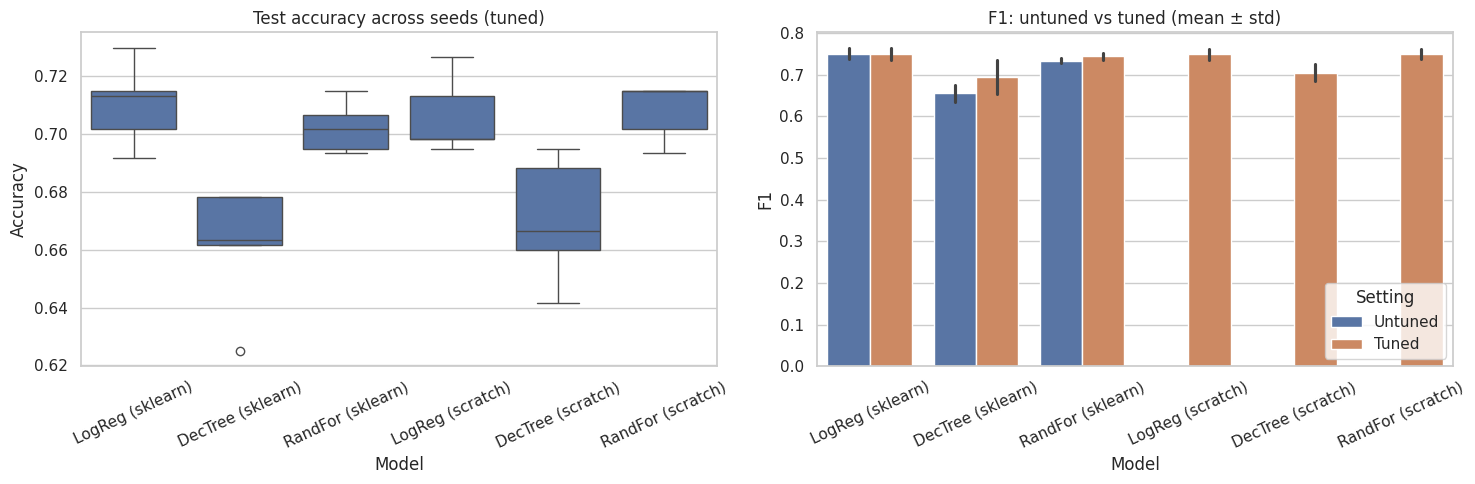

In [9]:
tuned = results[results.Setting == "Tuned"]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=tuned, x="Model", y="Accuracy", ax=ax[0]); ax[0].set_title("Test accuracy across seeds (tuned)")
ax[0].tick_params(axis="x", rotation=25)
order = results.groupby(["Model", "Setting"])["F1"].mean().reset_index()
sns.barplot(data=results, x="Model", y="F1", hue="Setting", errorbar="sd", ax=ax[1]); ax[1].set_title("F1: untuned vs tuned (mean ± std)")
ax[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.savefig("seed_results.png", dpi=150); plt.show()

In [10]:
display(best_params[best_params.Seed == SEEDS[0]].reset_index(drop=True))
print("Hyperparameters chosen per seed are in Best_Params_All_Seeds.csv")

,Seed,Model,CV_AUC,Params
0,0,LogReg (sklearn),0.794406,"{'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}"
1,0,DecTree (sklearn),0.712523,"{'criterion': 'gini', 'max_depth': 5, 'min_sam..."
2,0,RandFor (sklearn),0.775123,"{'max_depth': 6, 'max_features': 'sqrt', 'min_..."
3,0,LogReg (scratch),0.794263,"{'lr': 0.2, 'l2': 0.01, 'n_iter': 800}"
4,0,DecTree (scratch),0.729451,"{'max_depth': 7, 'min_samples_leaf': 20, 'rand..."
5,0,RandFor (scratch),0.771414,"{'n_estimators': 100, 'max_depth': 6, 'min_sam..."


Hyperparameters chosen per seed are in Best_Params_All_Seeds.csv


## 6. Best model → feature importance, risk tiers, landing policy, safety heatmap
The best model is the tuned model with the highest **mean F1 across seeds**. It is refit on seed 42's training split for the downstream analysis.

Best model (mean F1 over seeds): LogReg (sklearn)
{'Accuracy': 0.7133, 'Precision': 0.7244, 'Recall': 0.7727, 'F1': 0.7478, 'ROC_AUC': np.float64(0.7613)}


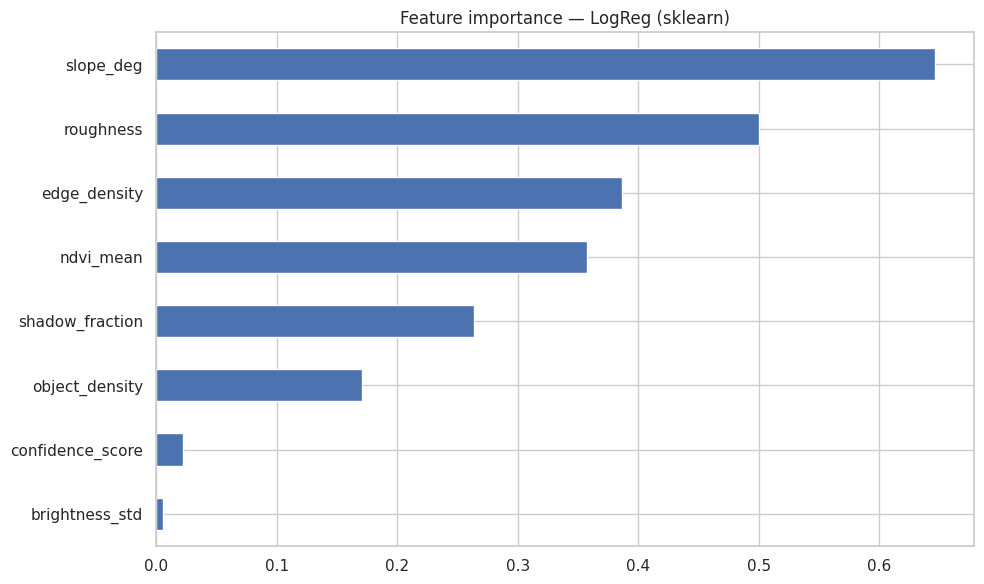

In [11]:
best_name = tuned.groupby("Model")["F1"].mean().idxmax()
print("Best model (mean F1 over seeds):", best_name)

SEED = 42
Xtr, Xte, ytr, yte = train_test_split(Xa, ya, test_size=TEST_SIZE, stratify=ya, random_state=SEED)
sc = StandardScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)

if best_name in SK_GRIDS:
    est, grid = SK_GRIDS[best_name]
    if "random_state" in est.get_params(): est.set_params(random_state=SEED)
    final = GridSearchCV(est, grid, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                         scoring="roc_auc", n_jobs=-1).fit(Xtr_s, ytr).best_estimator_
else:
    cls, grid = SCRATCH_GRIDS[best_name]
    params, _ = scratch_grid_search(cls, grid, Xtr_s, ytr, SEED)
    kw = dict(params)
    if cls is MyRandomForest: kw["n_estimators"] = 100
    if cls is not MyLogisticRegression: kw["random_state"] = SEED
    final = cls(**kw).fit(Xtr_s, ytr)

p_safe = final.predict_proba(Xte_s)[:, 1]
print({k: round(v, 4) for k, v in metrics(yte, p_safe).items()})

imp = getattr(final, "feature_importances_", None)
if imp is None and hasattr(final, "coef_"): imp = np.abs(final.coef_[0])
if imp is None and hasattr(final, "w"):     imp = np.abs(final.w)
imp = pd.Series(imp, index=FEATURES).sort_values()
imp.plot(kind="barh", title=f"Feature importance — {best_name}"); plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150); plt.show()

In [12]:
def risk_tier(p):
    if p >= 0.80: return "Low risk"
    if p >= 0.60: return "Medium risk"
    if p >= 0.40: return "High risk"
    return "Critical risk"

POLICY = {"Low risk": "LAND", "Medium risk": "LAND WITH CAUTION (slow descent, re-verify)",
          "High risk": "HOVER & RE-SCAN", "Critical risk": "ABORT — find another zone"}

out = pd.DataFrame(Xte, columns=FEATURES)
out["true_label"] = yte
out["P_safe"] = p_safe
out["risk_tier"] = out.P_safe.map(risk_tier)
out["action"] = out.risk_tier.map(POLICY)
print(out.risk_tier.value_counts())
out.head()

risk_tier
Medium risk      180
High risk        170
Critical risk    168
Low risk          82
Name: count, dtype: int64


,slope_deg,roughness,edge_density,ndvi_mean,shadow_fraction,brightness_std,object_density,confidence_score,true_label,P_safe,risk_tier,action
0,16.123392,0.354920,0.198261,0.502038,0.210016,0.043572,0.129337,0.811209,1,0.400760,High risk,HOVER & RE-SCAN
1,2.611276,0.323170,0.258362,0.003670,0.205049,0.110482,0.089008,0.604144,1,0.661623,Medium risk,"LAND WITH CAUTION (slow descent, re-verify)"
2,4.035636,0.291343,0.634067,0.162230,0.366634,0.212260,0.261199,0.619151,0,0.367754,Critical risk,ABORT — find another zone
3,5.265705,0.170829,0.242645,0.045356,0.135307,0.124164,0.164566,0.863461,1,0.725376,Medium risk,"LAND WITH CAUTION (slow descent, re-verify)"
4,13.804134,0.155732,0.431476,0.098938,0.173856,0.075557,0.165745,0.694969,0,0.354786,Critical risk,ABORT — find another zone


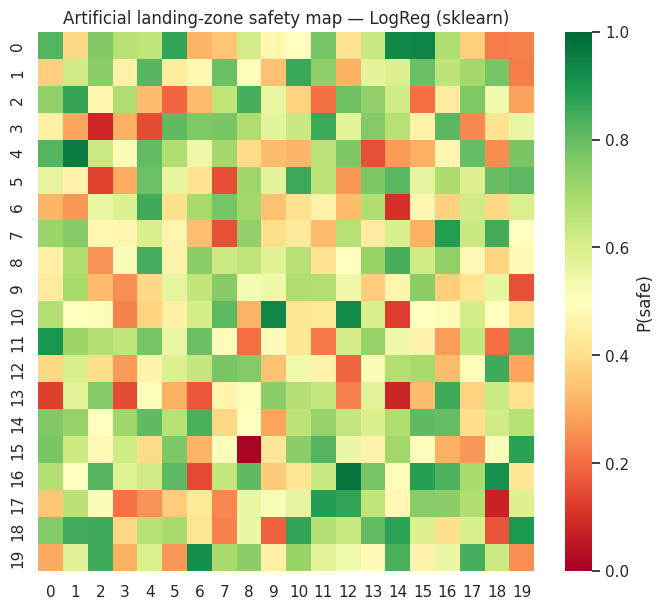

In [13]:
# Artificial 20x20 grid (the dataset has no coordinates) filled with test-set probabilities
rng = np.random.RandomState(SEED)
pick = rng.choice(len(out), 400, replace=len(out) < 400)
grid_p = out.P_safe.values[pick].reshape(20, 20)
plt.figure(figsize=(8, 7))
sns.heatmap(grid_p, cmap="RdYlGn", vmin=0, vmax=1, cbar_kws={"label": "P(safe)"})
plt.title(f"Artificial landing-zone safety map — {best_name}")
plt.savefig("safety_heatmap.png", dpi=150); plt.show()

## 7. Save outputs

In [14]:
df.to_csv("Landing_Zone_Dataset.csv", index=False)
results.to_csv("Seed_Results_All.csv", index=False)
summary.to_csv("Model_Comparison_Tuned_vs_Untuned.csv")
best_params.to_csv("Best_Params_All_Seeds.csv", index=False)
out.to_csv("Landing_Zone_Final_Output_v2.csv", index=False)
print("Saved: Landing_Zone_Dataset.csv, Seed_Results_All.csv, Model_Comparison_Tuned_vs_Untuned.csv, Best_Params_All_Seeds.csv, Landing_Zone_Final_Output_v2.csv")

Saved: Landing_Zone_Dataset.csv, Seed_Results_All.csv, Model_Comparison_Tuned_vs_Untuned.csv, Best_Params_All_Seeds.csv, Landing_Zone_Final_Output_v2.csv


## 8. Reflection
* **Tuning** changes the models only a little when the features are noisy — compare the *gain* table above before claiming an improvement; if gain is smaller than the seed-to-seed std it is not significant.
* **Seeds**: a single 80/20 split can move accuracy by a couple of points; the mean ± std over 5 seeds is the honest number to report.
* **Scratch vs sklearn**: close scores confirm the from-scratch implementations are correct; sklearn is faster and has more regularisation options.
* **Limitations**: tabular features only, no spatial coordinates, artificial heatmap grid.